C:\Users\admin\AppData\Local\Temp\ipykernel_19344\649089142.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y=metric, data=temp_df, ax=ax, palette=[colors[i]], alpha=0.85, edgecolor='black')
C:\Users\admin\AppData\Local\Temp\ipykernel_19344\649089142.py:36: UserWarning: 
The palette list has fewer values (1) than needed (5) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(x='Model', y=metric, data=temp_df, ax=ax, palette=[colors[i]], alpha=0.85, edgecolor='black')
C:\Users\admin\AppData\Local\Temp\ipykernel_19344\649089142.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y=metric, data=temp_df, ax=ax, palette=[colors[i]], alpha=0.85, e

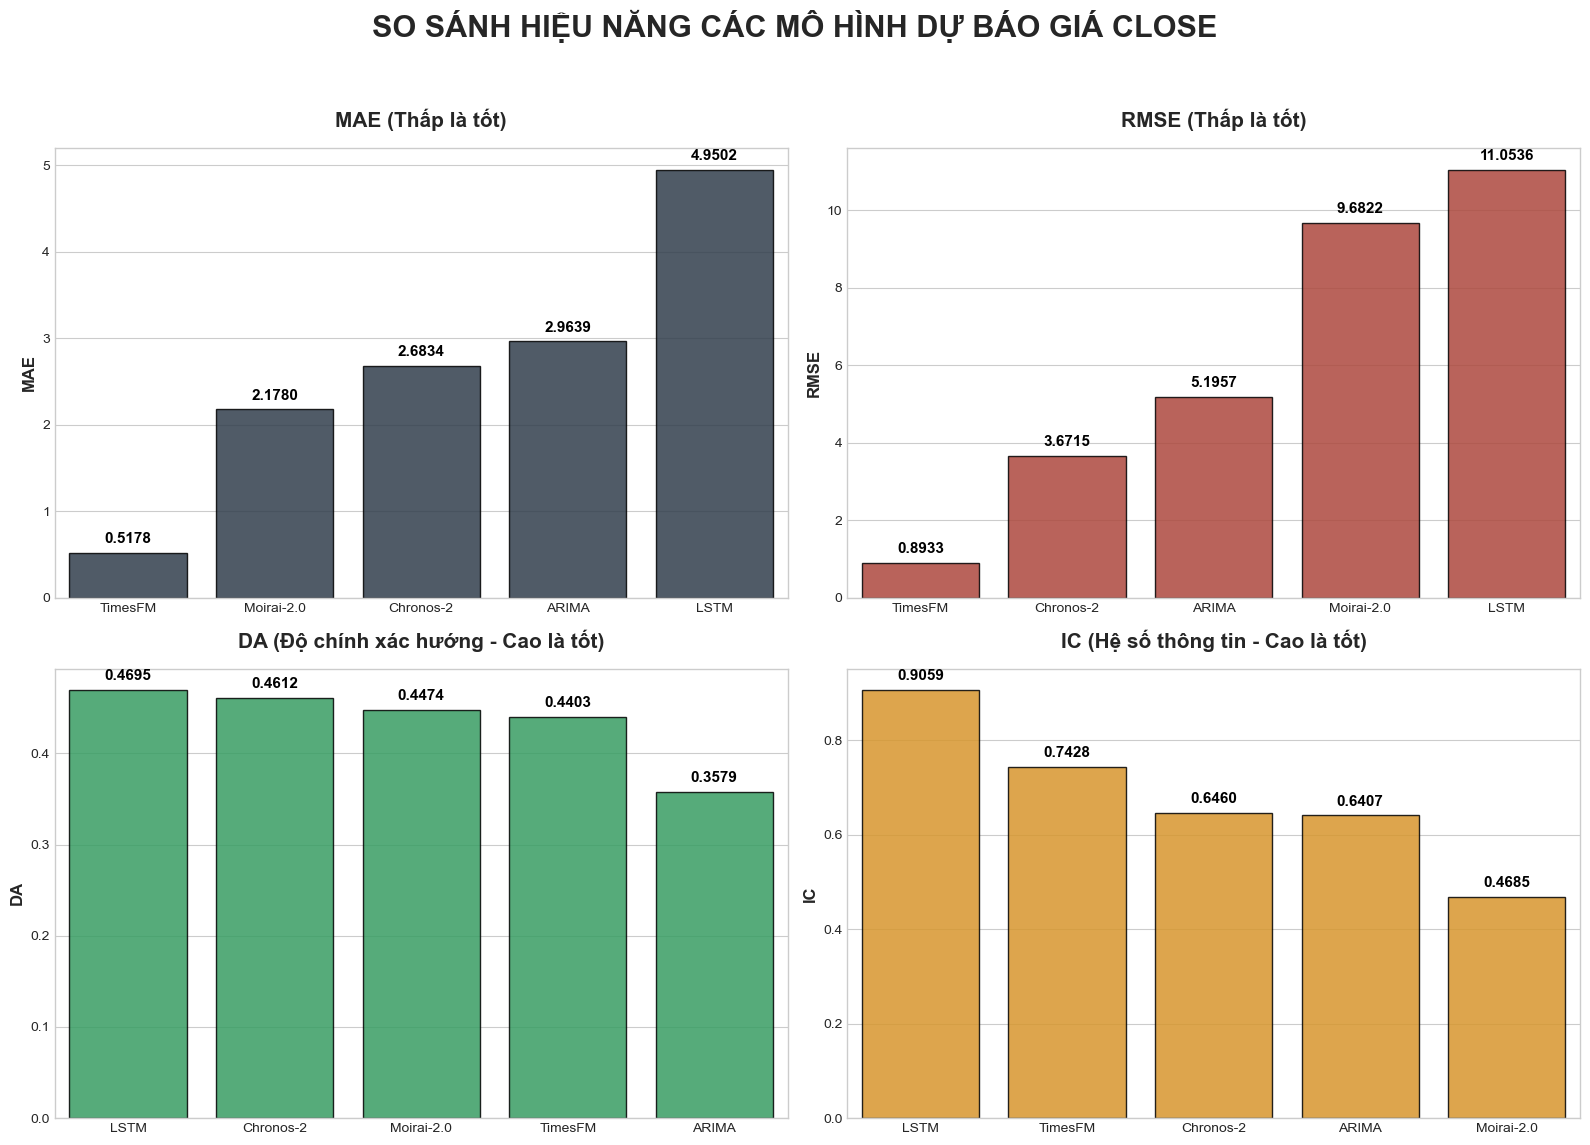

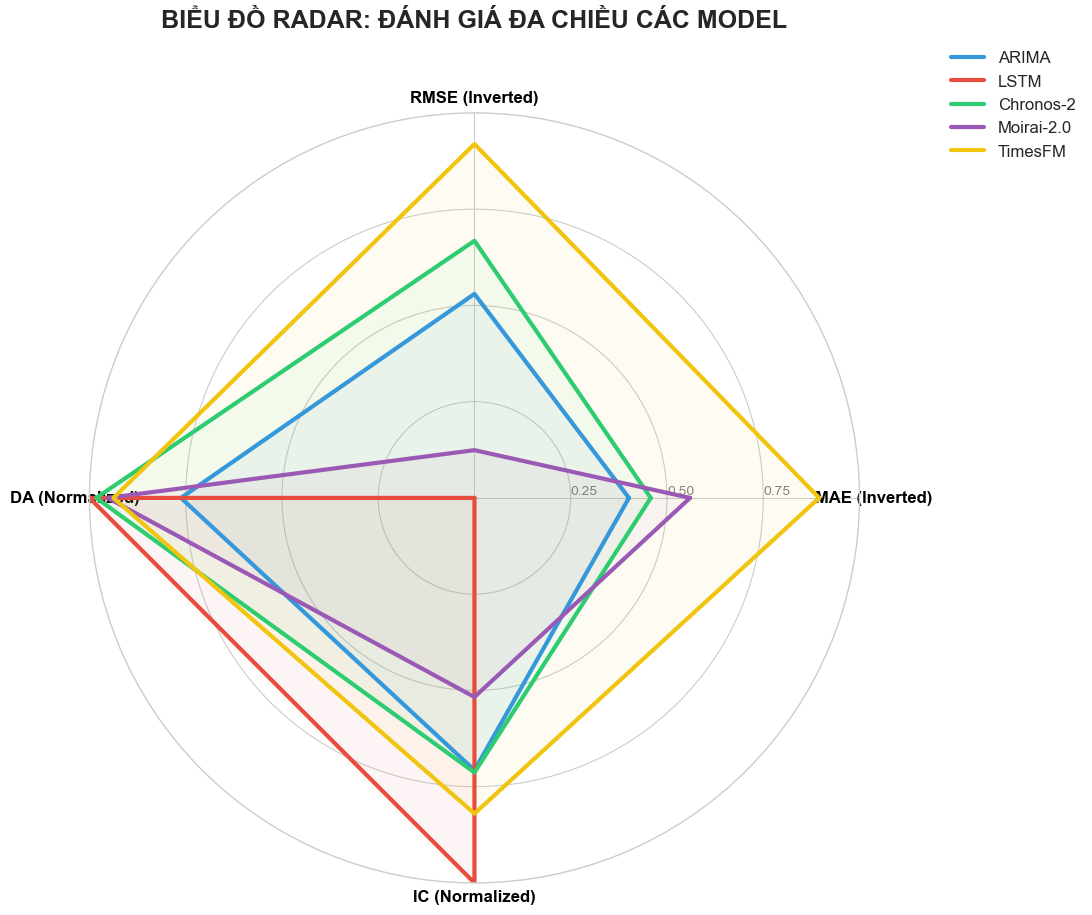

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Khởi tạo dữ liệu từ kết quả thực nghiệm của bạn
data = {
    "Model": ["ARIMA", "LSTM", "Chronos-2", "Moirai-2.0", "TimesFM"],
    "MAE": [2.963898, 4.950202, 2.683360, 2.177995, 0.517750],
    "RMSE": [5.195681, 11.053562, 3.671537, 9.682169, 0.893318],
    "DA": [0.357942, 0.469518, 0.461222, 0.447370, 0.440292],
    "IC": [0.640710, 0.905943, 0.646039, 0.468504, 0.742799]
}

df = pd.DataFrame(data)

# Cấu hình phong cách biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH DỰ BÁO GIÁ CLOSE', fontsize=22, fontweight='bold', y=0.98)

metrics = ['MAE', 'RMSE', 'DA', 'IC']
# Màu sắc chuyên nghiệp cho từng chỉ số
colors = ['#2c3e50', '#c0392b', '#27ae60', '#f39c12']
titles = ['MAE (Thấp là tốt)', 'RMSE (Thấp là tốt)', 
          'DA (Độ chính xác hướng - Cao là tốt)', 'IC (Hệ số thông tin - Cao là tốt)']

# Vẽ 4 biểu đồ cột
for i, metric in enumerate(metrics):
    ax = axes[i // 2, i % 2]
    # Sắp xếp để biểu đồ trông gọn gàng hơn
    # MAE/RMSE: thấp nhất nằm đầu | DA/IC: cao nhất nằm đầu
    ascending = True if metric in ['MAE', 'RMSE'] else False
    temp_df = df.sort_values(metric, ascending=ascending)
    
    sns.barplot(x='Model', y=metric, data=temp_df, ax=ax, palette=[colors[i]], alpha=0.85, edgecolor='black')
    
    ax.set_title(titles[i], fontsize=15, fontweight='bold', pad=15)
    ax.set_xlabel('', fontsize=12)
    ax.set_ylabel(metric, fontsize=12, fontweight='bold')
    
    # Thêm giá trị cụ thể lên đầu mỗi cột
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.4f}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', fontsize=11, color='black', 
                    fontweight='bold', xytext=(0, 10), 
                    textcoords='offset points')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# --- VẼ BIỂU ĐỒ RADAR (Radar Chart) ---

# Chuẩn hóa dữ liệu (0-1) để vẽ Radar
# Vì MAE/RMSE thấp là tốt nên ta đảo ngược giá trị: 1 - (val/max)
radar_df = df.copy()
radar_df['MAE_Score'] = 1 - (radar_df['MAE'] / radar_df['MAE'].max())
radar_df['RMSE_Score'] = 1 - (radar_df['RMSE'] / radar_df['RMSE'].max())
radar_df['DA_Score'] = radar_df['DA'] / radar_df['DA'].max()
radar_df['IC_Score'] = radar_df['IC'] / radar_df['IC'].max()

categories = ['MAE (Inverted)', 'RMSE (Inverted)', 'DA (Normalized)', 'IC (Normalized)']
N = len(categories)

angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig_radar = plt.figure(figsize=(10, 10))
ax_radar = fig_radar.add_subplot(111, polar=True)

# Vẽ từng Model lên Radar
model_colors = ['#3498db', '#e74c3c', '#2ecc71', '#9b59b6', '#f1c40f']

for i, (index, row) in enumerate(radar_df.iterrows()):
    values = [row['MAE_Score'], row['RMSE_Score'], row['DA_Score'], row['IC_Score']]
    values += values[:1]
    ax_radar.plot(angles, values, linewidth=3, linestyle='solid', label=row['Model'], color=model_colors[i])
    ax_radar.fill(angles, values, alpha=0.05, color=model_colors[i])

# Cấu hình trục Radar
plt.xticks(angles[:-1], categories, color='black', size=12, fontweight='bold')
ax_radar.set_rlabel_position(0)
plt.yticks([0.25, 0.5, 0.75], ["0.25", "0.50", "0.75"], color="grey", size=10)
plt.ylim(0, 1)

plt.title('BIỂU ĐỒ RADAR: ĐÁNH GIÁ ĐA CHIỀU CÁC MODEL', size=18, fontweight='bold', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=12)

plt.show()